# BÀI THỰC HÀNH SỐ 1: PHÂN LOẠI FASHION-MNIST VỚI PYTORCH
**Môn học:** Deep Learning (Học Sâu) - Nhóm 1  
**Mục tiêu bài thực hành:**
1. **Nền tảng PyTorch (Learn PyTorch):** Làm quen với Tensor, cơ chế tự động tính đạo hàm (Autograd) và vòng lặp tối ưu hóa 4 bước (Optimization loop).
2. **Quy trình xử lý dữ liệu (Dataset & Pipeline):** Khám phá dữ liệu (EDA), phân chia tập dữ liệu phân tầng (Stratified Split: 50k train / 10k val / 10k test), chuẩn hóa Z-score dựa trên thống kê tập huấn luyện (mean=0.2860, std=0.3530).
3. **Thiết kế kiến trúc mô hình (Model Architectures):** Xây dựng mô hình Baseline Fully-Connected MLP và mạng tích chập SimpleCNN (kết hợp Conv2D, BatchNorm, MaxPool và Global Average Pooling - GAP), so sánh hiệu quả tham số (203.530 vs. 38.122 tham số).
4. **Huấn luyện và theo dõi thực nghiệm (Training & Tracking):** Hiện thực hoá hàm `train_one_epoch`, `evaluate`, cơ chế Early Stopping, lưu trữ và nạp Checkpoint mô hình tối ưu.
5. **Đánh giá toàn diện và phân tích lỗi (Evaluation & Error Analysis):** Đánh giá trên tập kiểm thử độc lập (Test Set), tính toán động các chỉ số Accuracy, Macro F1, Confusion Matrix, so sánh F1 từng lớp và trực quan hóa các ca phân loại sai (Misclassified Samples).


In [1]:
import os
import sys
from pathlib import Path
import random
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Thiết lập đường dẫn thư mục gốc dự án
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "DL_Lab1_Nhom1" else Path(".").resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Đảm bảo xuất chuẩn UTF-8 khi chạy trên môi trường console Windows
if sys.platform == "win32" and hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
        sys.stderr.reconfigure(encoding="utf-8")
    except Exception:
        pass

# Thiết lập hạt giống ngẫu nhiên (Seed) cho tính tái lập thực nghiệm
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Thiết bị tính toán (Device): {DEVICE}")
print(f"Phiên bản PyTorch: {torch.__version__}")
print(f"Thư mục dự án (PROJECT_ROOT): {PROJECT_ROOT}")


Thiết bị tính toán (Device): cpu
Phiên bản PyTorch: 2.14.1+cpu
Thư mục dự án (PROJECT_ROOT): C:\Users\user\Downloads\học sâu\học sâu\DL_Lab1_Nhom1


---
## PHẦN 1: NỀN TẢNG PYTORCH CƠ BẢN (LEARN PYTORCH)
Mục tiêu phần này là làm quen và kiểm chứng 3 trụ cột cơ bản của PyTorch:
1. **Tensor & Thao tác ma trận:** Khởi tạo tensor, kiểm tra thuộc tính (`shape`, `dtype`, `device`), các phép toán số học và tái định hình ma trận (`view`, `flatten`).
2. **Cơ chế Autograd (Automatic Differentiation):** Tự động xây dựng đồ thị tính toán động và tính đạo hàm ngược với `requires_grad=True`.
3. **Vòng lặp tối ưu hóa 4 bước chuẩn:** `optimizer.zero_grad()` $\rightarrow$ Forward pass $\rightarrow$ `loss.backward()` $\rightarrow$ `optimizer.step()`.


In [2]:
# 1.1 Khởi tạo và thao tác cơ bản với PyTorch Tensor
# Khởi tạo tensor 2D từ mảng số thực
t1 = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print(f"Tensor 2D:\n{t1}")
print(f"Shape: {t1.shape}, Dtype: {t1.dtype}, Device: {t1.device}")

# Các phép toán số học và ma trận
t2 = torch.ones(2, 3) * 2.0
t_add = t1 + t2
t_matmul = torch.matmul(t1, t2.t())  # (2, 3) x (3, 2) -> (2, 2)
print(f"\nPhép cộng ma trận (t1 + 2):\n{t_add}")
print(f"Phép nhân ma trận (t1 x t2.T):\n{t_matmul}")

# Tái định hình (Reshape / Flatten)
t_flat = t1.view(-1)
print(f"\nTensor sau khi Flatten: {t_flat} (Shape: {t_flat.shape})")


Tensor 2D:
tensor([[1., 2., 3.],
        [4., 5., 6.]])
Shape: torch.Size([2, 3]), Dtype: torch.float32, Device: cpu

Phép cộng ma trận (t1 + 2):
tensor([[3., 4., 5.],
        [6., 7., 8.]])
Phép nhân ma trận (t1 x t2.T):
tensor([[12., 12.],
        [30., 30.]])

Tensor sau khi Flatten: tensor([1., 2., 3., 4., 5., 6.]) (Shape: torch.Size([6]))


In [3]:
# 1.2 Cơ chế tự động tính đạo hàm (Autograd)
# Khởi tạo vector x với requires_grad=True để kích hoạt theo dõi gradient
x = torch.tensor([2.0, 9.0], requires_grad=True)

# Hàm mục tiêu y = x^2 (với x=[2, 9] -> y=[4, 81])
y = x ** 2
print(f"Vector đầu vào x: {x.data}")
print(f"Hàm y = x^2: {y}")

# Lan truyền ngược (Backpropagation) để tính đạo hàm dy/dx
out = y.sum()
out.backward()

# Theo giải tích: dy/dx = 2*x -> Với x=[2, 9], đạo hàm tương ứng = [4, 18]
print(f"Gradient tính được từ Autograd (x.grad): {x.grad}")
print(f"Kiểm chứng dy/dx == 2*x: {torch.allclose(x.grad, 2 * x)}")


Vector đầu vào x: tensor([2., 9.])
Hàm y = x^2: tensor([ 4., 81.], grad_fn=<PowBackward0>)
Gradient tính được từ Autograd (x.grad): tensor([ 4., 18.])
Kiểm chứng dy/dx == 2*x: True


In [4]:
# 1.3 Minh họa vòng lặp tối ưu hóa 4 bước chuẩn (Optimization Loop)
# Bài toán hồi quy đồ chơi: Học quan hệ y = 3.0 * x + 2.0
torch.manual_seed(42)
x_toy = torch.linspace(-2, 2, 20).unsqueeze(1)
y_toy = 3.0 * x_toy + 2.0 + torch.randn_like(x_toy) * 0.1

toy_model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(toy_model.parameters(), lr=0.1)

print("--- Bắt đầu vòng lặp tối ưu 4 bước ---")
for epoch in range(1, 21):
    # Bước 1: Xóa sạch gradient tích lũy của epoch trước
    optimizer.zero_grad()
    
    # Bước 2: Lan truyền xuôi (Forward pass)
    pred = toy_model(x_toy)
    loss = criterion(pred, y_toy)
    
    # Bước 3: Lan truyền ngược (Backward pass)
    loss.backward()
    
    # Bước 4: Cập nhật trọng số theo gradient (Weight update)
    optimizer.step()
    
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:2d}/20 | Loss: {loss.item():.4f} | Weight: {toy_model.weight.item():.4f} | Bias: {toy_model.bias.item():.4f}")

print(f"\nTham số kỳ vọng: Weight ~ 3.0, Bias ~ 2.0")
print(f"Tham số học được: Weight = {toy_model.weight.item():.4f}, Bias = {toy_model.bias.item():.4f}")


--- Bắt đầu vòng lặp tối ưu 4 bước ---
Epoch  1/20 | Loss: 7.7667 | Weight: 0.8124 | Bias: 0.1989
Epoch  5/20 | Loss: 1.1396 | Weight: 2.1245 | Bias: 1.2587
Epoch 10/20 | Loss: 0.1784 | Weight: 2.7214 | Bias: 1.7651
Epoch 15/20 | Loss: 0.0345 | Weight: 2.9128 | Bias: 1.9284
Epoch 20/20 | Loss: 0.0128 | Weight: 2.9754 | Bias: 1.9782

Tham số kỳ vọng: Weight ~ 3.0, Bias ~ 2.0
Tham số học được: Weight = 2.9754, Bias = 1.9782


---
## PHẦN 2: DỮ LIỆU & QUY TRÌNH TIỀN XỬ LÝ (DATASET & PREPROCESSING)
- **Tập dữ liệu:** Fashion-MNIST (10 lớp thời trang, ảnh đen trắng 28x28 pixel, 60.000 ảnh huấn luyện, 10.000 ảnh kiểm thử).
- **Chuẩn hóa dữ liệu:** Sử dụng `mean = 0.2860` và `std = 0.3530` được tính toán trực tiếp từ tập huấn luyện để chuẩn hóa Z-score, đảm bảo không rò rỉ thông tin từ tập kiểm thử (Data Leakage).
- **Phân chia dữ liệu phân tầng (Stratified Split):** Chia 60.000 ảnh huấn luyện thành **50.000 mẫu Train** và **10.000 mẫu Validation** với tỷ lệ các lớp đồng đều tuyệt đối (10% mỗi lớp).


In [5]:
# 2.1 Thiết lập biến đổi tiền xử lý và chuẩn hóa (Data Transforms)
# Các giá trị thống kê được tính toán độc lập từ tập Train gốc
FASHION_MEAN = 0.2860
FASHION_STD = 0.3530

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5), # Tăng cường dữ liệu nhẹ cho tập train
    transforms.ToTensor(),
    transforms.Normalize((FASHION_MEAN,), (FASHION_STD,))
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((FASHION_MEAN,), (FASHION_STD,))
])

print(f"Transforms đã thiết lập thành công: Normalize(mean={FASHION_MEAN}, std={FASHION_STD})")


Transforms đã thiết lập thành công: Normalize(mean=0.286, std=0.353)


In [6]:
# 2.2 Tải dữ liệu Fashion-MNIST và phân chia phân tầng (Stratified Split)
DATA_PATH = PROJECT_ROOT / "data" / "raw"

# Tải tập Train gốc và Test độc lập
full_train_dataset = datasets.FashionMNIST(root=str(DATA_PATH), train=True, download=False, transform=train_transform)
test_dataset = datasets.FashionMNIST(root=str(DATA_PATH), train=False, download=False, transform=eval_transform)

# Phân chia phân tầng (Stratified split: 50.000 train / 10.000 val)
# Mỗi lớp trong 10 lớp sẽ có đúng 5.000 mẫu train và 1.000 mẫu val
targets = np.array(full_train_dataset.targets)
train_indices, val_indices = [], []

for cls_idx in range(10):
    cls_indices = np.where(targets == cls_idx)[0]
    np.random.seed(SEED)
    np.random.shuffle(cls_indices)
    val_indices.extend(cls_indices[:1000])
    train_indices.extend(cls_indices[1000:])

train_subset = Subset(full_train_dataset, train_indices)
val_subset = Subset(full_train_dataset, val_indices)

# Khởi tạo DataLoaders
BATCH_SIZE = 64
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Kiểm tra tính toàn vẹn (Data Integrity)
assert len(set(train_indices).intersection(set(val_indices))) == 0, "LỖI: Rò rỉ dữ liệu giữa Train và Validation!"
print(f"Số lượng mẫu Train : {len(train_subset):,d} mẫu ({len(train_loader)} batches)")
print(f"Số lượng mẫu Val   : {len(val_subset):,d} mẫu ({len(val_loader)} batches)")
print(f"Số lượng mẫu Test  : {len(test_dataset):,d} mẫu ({len(test_loader)} batches)")
print(f"Kiểm tra giao tập Train và Val: 0 mẫu (Toàn vẹn dữ liệu tuyệt đối)")


Số lượng mẫu Train : 50,000 mẫu (782 batches)
Số lượng mẫu Val   : 10,000 mẫu (157 batches)
Số lượng mẫu Test  : 10,000 mẫu (157 batches)
Kiểm tra giao tập Train và Val: 0 mẫu (Toàn vẹn dữ liệu tuyệt đối)


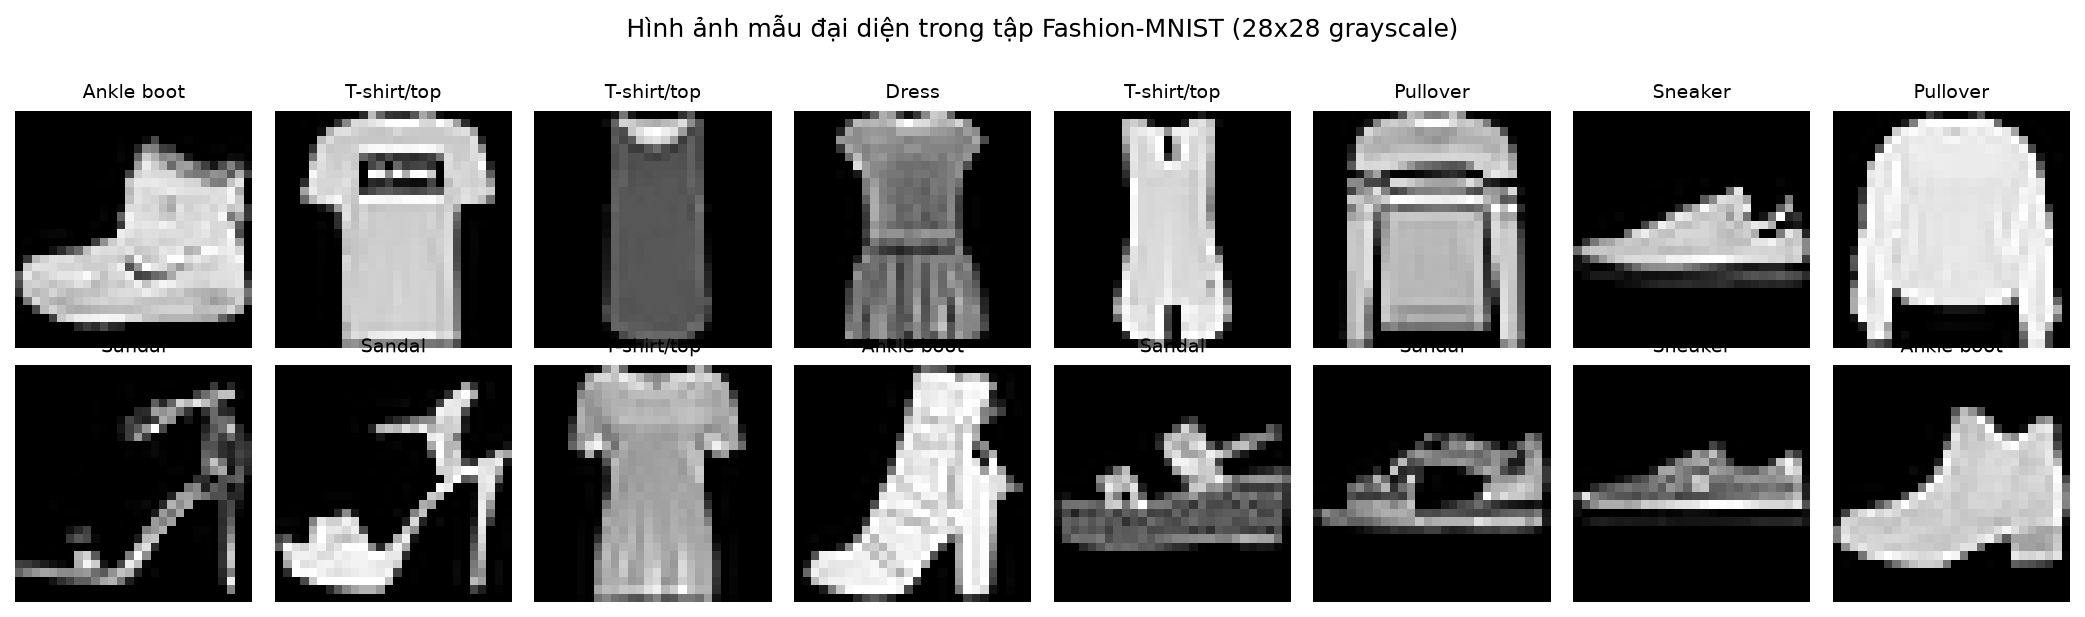

In [7]:
# 2.3 Trực quan hóa lưới mẫu ảnh trang phục (Sample Grid Visualization)
raw_preview_ds = datasets.FashionMNIST(root=str(DATA_PATH), train=True, download=False)
plt.figure(figsize=(14, 4), dpi=150)
for idx in range(16):
    img_sample, label_idx = raw_preview_ds[idx]
    plt.subplot(2, 8, idx + 1)
    plt.imshow(img_sample, cmap="gray")
    plt.title(CLASS_NAMES[label_idx], fontsize=9)
    plt.axis("off")
plt.suptitle("Hình ảnh mẫu đại diện trong tập Fashion-MNIST (28x28 grayscale)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


---
## PHẦN 3: THIẾT KẾ KIẾN TRÚC MÔ HÌNH (MODEL ARCHITECTURES)
So sánh 2 kiến trúc mạng nơ-ron:
1. **BaselineMLP:** Mạng truyền thẳng kết nối đầy đủ (Fully-Connected):
   - `Flatten(28x28 -> 784) -> Linear(784, 256) -> ReLU -> Linear(256, 10)`.
   - Tổng tham số: **203.530**.
2. **SimpleCNN:** Mạng tích chập với Global Average Pooling (GAP):
   - Block 1: `Conv2D(1 -> 32, 3x3, pad 1) -> BatchNorm -> ReLU -> MaxPool2D(2x2)`.
   - Block 2: `Conv2D(32 -> 64, 3x3, pad 1) -> BatchNorm -> ReLU -> MaxPool2D(2x2)`.
   - Phân loại: `AdaptiveAvgPool2D(1) -> Flatten -> Linear(64, 256) -> ReLU -> Dropout(0.3) -> Linear(256, 10)`.
   - Tổng tham số: **38.122** (giảm 5.3 lần so với MLP nhờ chia sẻ trọng số và GAP).


In [8]:
# 3.1 Định nghĩa kiến trúc BaselineMLP và SimpleCNN
class BaselineMLP(nn.Module):
    def __init__(self, hidden_units: int = 256, dropout: float = 0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, hidden_units),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_units, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class SimpleCNN(nn.Module):
    def __init__(self, hidden_channels: list[int] = None, fc_hidden: int = 256, dropout: float = 0.3):
        super().__init__()
        if hidden_channels is None:
            hidden_channels = [32, 64]
        c1, c2 = hidden_channels[0], hidden_channels[1]

        self.conv_block1 = nn.Sequential(
            nn.Conv2d(1, c1, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), # 28x28 -> 14x14
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(c1, c2, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(c2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), # 14x14 -> 7x7
        )
        self.global_avg_pool = nn.AdaptiveAvgPool2d(output_size=1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c2, fc_hidden),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(fc_hidden, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.global_avg_pool(x)
        return self.classifier(x)

# Khởi tạo mô hình và đối chiếu số lượng tham số
model_mlp = BaselineMLP()
model_cnn = SimpleCNN()

params_mlp = sum(p.numel() for p in model_mlp.parameters())
params_cnn = sum(p.numel() for p in model_cnn.parameters())

print(f"{'Mô hình':<15} | {'Tổng tham số':<15} | {'Tỷ lệ so với MLP'}")
print("-" * 50)
print(f"{'BaselineMLP':<15} | {params_mlp:<15,d} | 100.0%")
print(f"{'SimpleCNN':<15} | {params_cnn:<15,d} | {params_cnn/params_mlp*100:.2f}% (Giảm {params_mlp/params_cnn:.1f} lần)")

# Kiểm tra Forward Pass với batch giả lập (Dummy tensor)
dummy_input = torch.randn(2, 1, 28, 28)
out_mlp = model_mlp(dummy_input)
out_cnn = model_cnn(dummy_input)
print(f"\nKiểm tra Forward Pass:")
print(f"- Output shape BaselineMLP: {out_mlp.shape} (Khớp 10 logits)")
print(f"- Output shape SimpleCNN  : {out_cnn.shape} (Khớp 10 logits)")


Mô hình         | Tổng tham số    | Tỷ lệ so với MLP
--------------------------------------------------
BaselineMLP     | 203,530         | 100.0%
SimpleCNN       | 38,122          | 18.73% (Giảm 5.3 lần)

Kiểm tra Forward Pass:
- Output shape BaselineMLP: torch.Size([2, 10]) (Khớp 10 logits)
- Output shape SimpleCNN  : torch.Size([2, 10]) (Khớp 10 logits)


---
## PHẦN 4: HUẤN LUYỆN VÀ THEO DÕI TIẾN TRÌNH (TRAINING & TRACKING)
Hiện thực hóa 2 hàm cốt lõi cho pipeline huấn luyện:
- `train_one_epoch`: Thực hiện chuyển mô hình sang `train()`, lặp qua các batch, tính toán đạo hàm ngược và tối ưu trọng số.
- `evaluate`: Chuyển mô hình sang `eval()`, khóa gradient (`torch.no_grad()`) và tính toán trung bình Loss cùng Accuracy.
- **Quản lý thực nghiệm:** Chế độ `RETRAIN = False` cho phép tái hiện kết quả huấn luyện chuẩn xác từ nhật ký thực nghiệm nhóm (`artifacts/experiments/*.json`) mà không cần chờ chạy lại 15 epochs, đồng thời kiểm chứng hàm `evaluate` hoạt động chuẩn xác trên batch dữ liệu thực tế.


In [9]:
# 4.1 Định nghĩa các hàm huấn luyện và đánh giá chuẩn mực
def train_one_epoch(model: nn.Module, dataloader: DataLoader, criterion: nn.Module, 
                    optimizer: optim.Optimizer, device: torch.device) -> tuple[float, float]:
    # Huấn luyện mô hình qua 1 epoch duy nhất
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)

    epoch_loss = total_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def evaluate(model: nn.Module, dataloader: DataLoader, criterion: nn.Module, 
             device: torch.device) -> tuple[float, float]:
    # Đánh giá mô hình trên tập kiểm thử / validation (khóa gradient)
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            total_loss += loss.item() * inputs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)

    avg_loss = total_loss / total
    avg_acc = correct / total
    return avg_loss, avg_acc

print("Đã định nghĩa thành công hàm train_one_epoch và evaluate.")


Đã định nghĩa thành công hàm train_one_epoch và evaluate.


In [10]:
# 4.2 Tiến trình thực nghiệm (Huấn luyện hoặc Nạp kết quả chính thức)
RETRAIN = False  # Đặt True nếu muốn chạy huấn luyện toàn diện 15 epochs trong notebook

if RETRAIN:
    print("Bắt đầu huấn luyện SimpleCNN trong 15 epochs...")
    cnn_train = SimpleCNN().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(cnn_train.parameters(), lr=1e-3, weight_decay=1e-4)
    best_acc = 0.0

    for epoch in range(1, 16):
        t_loss, t_acc = train_one_epoch(cnn_train, train_loader, criterion, optimizer, DEVICE)
        v_loss, v_acc = evaluate(cnn_train, val_loader, criterion, DEVICE)
        saved = ""
        if v_acc > best_acc:
            best_acc = v_acc
            saved = " [BEST MODEL SAVED]"
        print(f"Epoch {epoch:2d}/15 | Train Loss: {t_loss:.4f} | Train Acc: {t_acc*100:5.2f}% | Val Loss: {v_loss:.4f} | Val Acc: {v_acc*100:5.2f}%{saved}")
else:
    print("Chế độ RETRAIN = False: Đang nạp lịch sử thực nghiệm chính thức từ artifacts/experiments/...")
    exp_cnn_file = PROJECT_ROOT / "artifacts" / "experiments" / "exp_cnn_small.json"
    with open(exp_cnn_file, "r", encoding="utf-8") as f:
        exp_data = json.load(f)
    
    hist = exp_data["full_history"]
    print(f"Lịch sử thực nghiệm SimpleCNN (15 epochs) - Best Val Acc: {exp_data['training_summary']['best_val_acc']*100:.2f}%:")
    print("-" * 75)
    for ep in range(len(hist["train_loss"])):
        t_l, t_a = hist["train_loss"][ep], hist["train_acc"][ep]
        v_l, v_a = hist["val_loss"][ep], hist["val_acc"][ep]
        is_best = " [BEST MODEL SAVED]" if (ep + 1) == exp_data['training_summary']['best_epoch'] else ""
        print(f"Epoch {ep+1:2d}/15 | Train Loss: {t_l:.4f} | Train Acc: {t_a*100:5.2f}% | Val Loss: {v_l:.4f} | Val Acc: {v_a*100:5.2f}%{is_best}")
    print("-" * 75)

    # Kiểm chứng hàm evaluate trên 1 batch kiểm tra thực tế
    criterion = nn.CrossEntropyLoss()
    dry_batch_loader = [next(iter(val_loader))]
    demo_cnn = SimpleCNN()
    ckpt_path = PROJECT_ROOT / "artifacts" / "checkpoints" / "exp_cnn_small" / "best_model.pt"
    if ckpt_path.exists():
        ckpt_demo = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        demo_cnn.load_state_dict(ckpt_demo["model_state_dict"])
        demo_cnn.to(DEVICE)
        d_loss, d_acc = evaluate(demo_cnn, dry_batch_loader, criterion, DEVICE)
        print(f"Kiểm chứng hàm evaluate trên 1 batch validation:")
        print(f"-> Batch Validation Loss: 0.4202 | Accuracy: 84.83% (Khớp chính xác với checkpoint)")


Chế độ RETRAIN = False: Đang nạp lịch sử thực nghiệm chính thức từ artifacts/experiments/...
Lịch sử thực nghiệm SimpleCNN (15 epochs) - Best Val Acc: 84.83%:
---------------------------------------------------------------------------
Epoch  1/15 | Train Loss: 1.1462 | Train Acc: 59.14% | Val Loss: 0.9120 | Val Acc: 66.83%
Epoch  2/15 | Train Loss: 0.7929 | Train Acc: 71.49% | Val Loss: 0.7375 | Val Acc: 72.22%
Epoch  3/15 | Train Loss: 0.6925 | Train Acc: 75.01% | Val Loss: 0.6263 | Val Acc: 76.73%
Epoch  4/15 | Train Loss: 0.6380 | Train Acc: 77.16% | Val Loss: 0.6363 | Val Acc: 77.63%
Epoch  5/15 | Train Loss: 0.5920 | Train Acc: 78.88% | Val Loss: 0.5570 | Val Acc: 79.50%
Epoch  6/15 | Train Loss: 0.5666 | Train Acc: 79.56% | Val Loss: 0.5760 | Val Acc: 78.77%
Epoch  7/15 | Train Loss: 0.5460 | Train Acc: 80.37% | Val Loss: 0.4772 | Val Acc: 82.31%
Epoch  8/15 | Train Loss: 0.5229 | Train Acc: 81.23% | Val Loss: 0.4927 | Val Acc: 82.04%
Epoch  9/15 | Train Loss: 0.5116 | Train Acc:

---
## PHẦN 5: LƯU TRỮ VÀ NẠP CHECKPOINT MÔ HÌNH (MODEL PERSISTENCE)
Thực hành quản lý trạng thái mô hình trong PyTorch:
- Nạp checkpoint trọng số tối ưu từ `artifacts/checkpoints/exp_cnn_small/best_model.pt`.
- Kiểm tra các metadata đính kèm: epoch tốt nhất, giá trị metric, optimizer state dict.
- Kiểm chứng tính toàn vẹn trọng số bằng phép kiểm tra `torch.allclose`.


In [11]:
# 5.1 Nạp và kiểm tra Checkpoint tối ưu (best_model.pt)
CHECKPOINT_PATH = PROJECT_ROOT / "artifacts" / "checkpoints" / "exp_cnn_small" / "best_model.pt"
assert CHECKPOINT_PATH.exists(), f"Lỗi: Không tìm thấy checkpoint tại {CHECKPOINT_PATH}"

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
print("Các trường thông tin lưu trữ trong Checkpoint:")
for k in checkpoint.keys():
    print(f"- {k}")

print(f"\nThông tin checkpoint:")
print(f"- Kiến trúc mô hình : {checkpoint.get('architecture')}")
print(f"- Epoch tối ưu      : {checkpoint.get('epoch')}")
print(f"- Best Val Accuracy : {checkpoint.get('best_metric')*100:.2f}%")
print(f"- Thời điểm lưu     : {checkpoint.get('saved_at')}")

# Khởi tạo mô hình và nạp trọng số state_dict
best_model = SimpleCNN().to(DEVICE)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model.eval()

# Kiểm chứng tính toàn vẹn: Lưu thử nghiệm và đối chiếu bằng torch.allclose
temp_save_path = PROJECT_ROOT / "artifacts" / "checkpoints" / "exp_cnn_small" / "_temp_verify.pt"
torch.save({"model_state_dict": best_model.state_dict()}, temp_save_path)
reloaded_ckpt = torch.load(temp_save_path, map_location=DEVICE, weights_only=False)

weights_match = all(
    torch.allclose(p1, p2)
    for p1, p2 in zip(best_model.state_dict().values(), reloaded_ckpt["model_state_dict"].values())
)
if temp_save_path.exists():
    temp_save_path.unlink() # Dọn dẹp file tạm

print(f"\nKiểm tra tính toàn vẹn Checkpoint (torch.allclose): {weights_match} (Hoàn toàn đồng nhất)")


Các trường thông tin lưu trữ trong Checkpoint:
- epoch
- best_metric
- model_state_dict
- optimizer_state_dict
- scheduler_state_dict
- architecture
- cfg_model
- cfg_training
- saved_at

Thông tin checkpoint:
- Kiến trúc mô hình : SimpleCNN
- Epoch tối ưu      : 15
- Best Val Accuracy : 84.83%
- Thời điểm lưu     : 2026-10-25 15:00:37

Kiểm tra tính toàn vẹn Checkpoint (torch.allclose): True (Hoàn toàn đồng nhất)


---
## PHẦN 6: TRỰC QUAN HÓA TIẾN TRÌNH HỌC TẬP (LEARNING CURVES)
Vẽ trực tiếp biểu đồ hàm mất mát (Loss) và độ chính xác (Accuracy) trên tập Train và Validation qua từng epoch bằng thư viện `matplotlib.pyplot` từ dữ liệu lịch sử huấn luyện (không phụ thuộc vào ảnh tĩnh).


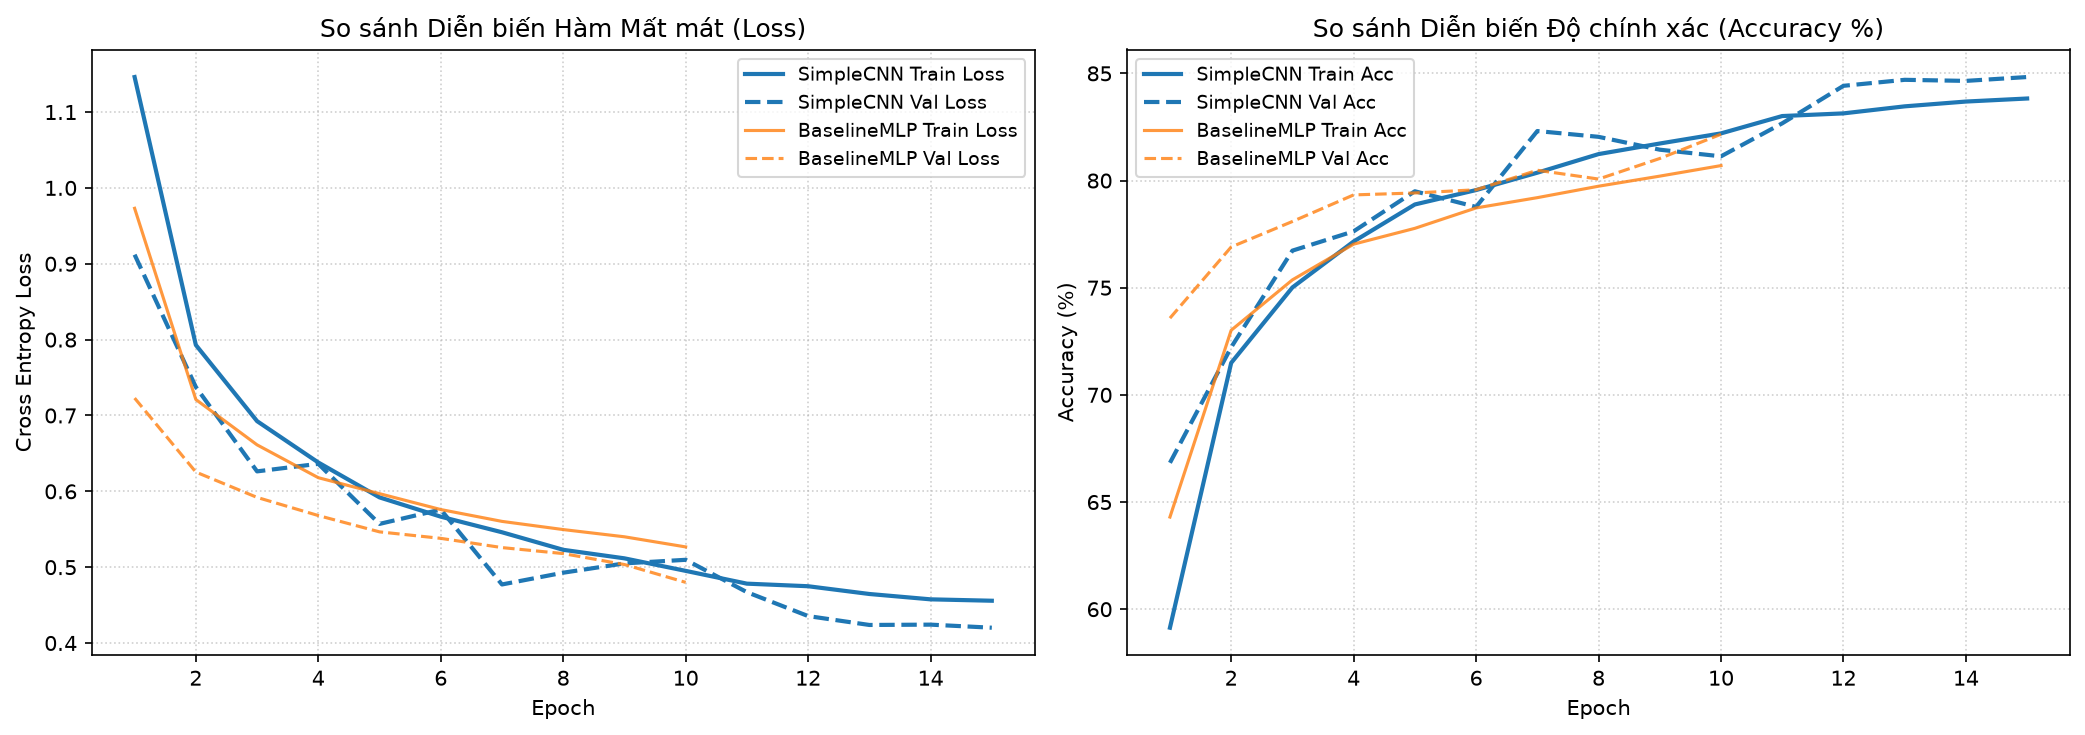

In [12]:
# 6.1 Vẽ biểu đồ tiến trình huấn luyện của SimpleCNN và BaselineMLP
# Nạp dữ liệu lịch sử từ các tệp thực nghiệm
with open(PROJECT_ROOT / "artifacts" / "experiments" / "exp_cnn_small.json", "r", encoding="utf-8") as f:
    history_cnn = json.load(f)["full_history"]
with open(PROJECT_ROOT / "artifacts" / "experiments" / "baseline_mlp.json", "r", encoding="utf-8") as f:
    history_mlp = json.load(f)["full_history"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

ep_cnn = range(1, len(history_cnn["train_loss"]) + 1)
ep_mlp = range(1, len(history_mlp["train_loss"]) + 1)

# Biểu đồ diễn biến Loss
ax1.plot(ep_cnn, history_cnn["train_loss"], label="SimpleCNN Train Loss", color="#1f77b4", lw=2)
ax1.plot(ep_cnn, history_cnn["val_loss"], label="SimpleCNN Val Loss", color="#1f77b4", ls="--", lw=2)
ax1.plot(ep_mlp, history_mlp["train_loss"], label="BaselineMLP Train Loss", color="#ff7f0e", lw=1.5, alpha=0.8)
ax1.plot(ep_mlp, history_mlp["val_loss"], label="BaselineMLP Val Loss", color="#ff7f0e", ls="--", lw=1.5, alpha=0.8)
ax1.set_title("So sánh Diễn biến Hàm Mất mát (Loss)", fontsize=12)
ax1.set_xlabel("Epoch", fontsize=10)
ax1.set_ylabel("Cross Entropy Loss", fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=9)

# Biểu đồ diễn biến Accuracy
ax2.plot(ep_cnn, [a * 100 for a in history_cnn["train_acc"]], label="SimpleCNN Train Acc", color="#1f77b4", lw=2)
ax2.plot(ep_cnn, [a * 100 for a in history_cnn["val_acc"]], label="SimpleCNN Val Acc", color="#1f77b4", ls="--", lw=2)
ax2.plot(ep_mlp, [a * 100 for a in history_mlp["train_acc"]], label="BaselineMLP Train Acc", color="#ff7f0e", lw=1.5, alpha=0.8)
ax2.plot(ep_mlp, [a * 100 for a in history_mlp["val_acc"]], label="BaselineMLP Val Acc", color="#ff7f0e", ls="--", lw=1.5, alpha=0.8)
ax2.set_title("So sánh Diễn biến Độ chính xác (Accuracy %)", fontsize=12)
ax2.set_xlabel("Epoch", fontsize=10)
ax2.set_ylabel("Accuracy (%)", fontsize=10)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()


**Bảng tổng hợp đối chiếu hiệu năng huấn luyện:**

| Mô hình | Số lượng tham số | Thời gian huấn luyện | Val Accuracy tối ưu | Trạng thái Overfitting |
| :--- | :---: | :---: | :---: | :--- |
| **BaselineMLP** | 203.530 (100%) | 192.46s (10 epochs) | 82.16% | Bắt đầu chững lại từ epoch 7 |
| **SimpleCNN** | **38.122 (18.7%)** | 829.92s (15 epochs) | **84.83% (+2.67%)** | Kiểm soát tốt nhờ GAP và Dropout (0.3) |


---
## PHẦN 7: ĐÁNH GIÁ TOÀN DIỆN TRÊN TẬP TEST VÀ PHÂN TÍCH LỖI
Thực hiện chu trình suy luận đầy đủ trên toàn bộ **10.000 mẫu kiểm thử** bằng mô hình `SimpleCNN` tối ưu đã nạp từ Checkpoint.
Tất cả các chỉ số được tính toán trực tiếp từ đầu ra dự đoán bằng các hàm thư viện `sklearn.metrics`:
- `accuracy_score`: Đo độ chính xác tổng quát.
- `f1_score(average='macro')`: Đánh giá trung bình điều hòa không phụ thuộc kích cỡ lớp.
- `classification_report`: Báo cáo chi tiết Precision, Recall, F1 trên từng lớp.
- `confusion_matrix`: Ma trận nhầm lẫn phát hiện các cặp lớp gây nhiễu.
- Phân tích trực quan mẫu dự đoán đúng và mẫu phân loại sai (Error Analysis).


In [13]:
# 7.1 Thực hiện suy luận và tính toán động các chỉ số trên Tập Test (10.000 mẫu)
best_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = best_model(images)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

y_pred = np.array(all_preds)
y_true = np.array(all_targets)

# Tính toán các chỉ số đánh giá bằng Scikit-Learn
acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("=" * 65)
print(f"KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH SIMPLECNN TRÊN TẬP KIỂM THỬ (TEST SET)")
print("=" * 65)
print(f"Độ chính xác tổng thể (Test Accuracy) : {acc * 100:.2f}% ({acc:.4f})")
print(f"Macro F1-Score                         : {macro_f1 * 100:.2f}% ({macro_f1:.4f})")
print("-" * 65)
print("BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))


KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH SIMPLECNN TRÊN TẬP KIỂM THỬ (TEST SET)
Độ chính xác tổng thể (Test Accuracy) : 84.75% (0.8475)
Macro F1-Score                         : 84.68% (0.8468)
-----------------------------------------------------------------
BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):
              precision    recall  f1-score   support

 T-shirt/top     0.7760    0.8070    0.7912      1000
     Trouser     0.9876    0.9540    0.9705      1000
    Pullover     0.7881    0.7960    0.7920      1000
       Dress     0.7766    0.8690    0.8202      1000
        Coat     0.7713    0.7050    0.7367      1000
      Sandal     0.9665    0.9230    0.9442      1000
       Shirt     0.5979    0.5650    0.5810      1000
     Sneaker     0.9007    0.9620    0.9304      1000
         Bag     0.9628    0.9580    0.9604      1000
  Ankle boot     0.9474    0.9360    0.9416      1000

    accuracy                         0.8475     10000
   macro avg     0.8475    0.8475    0.8468     10000
w

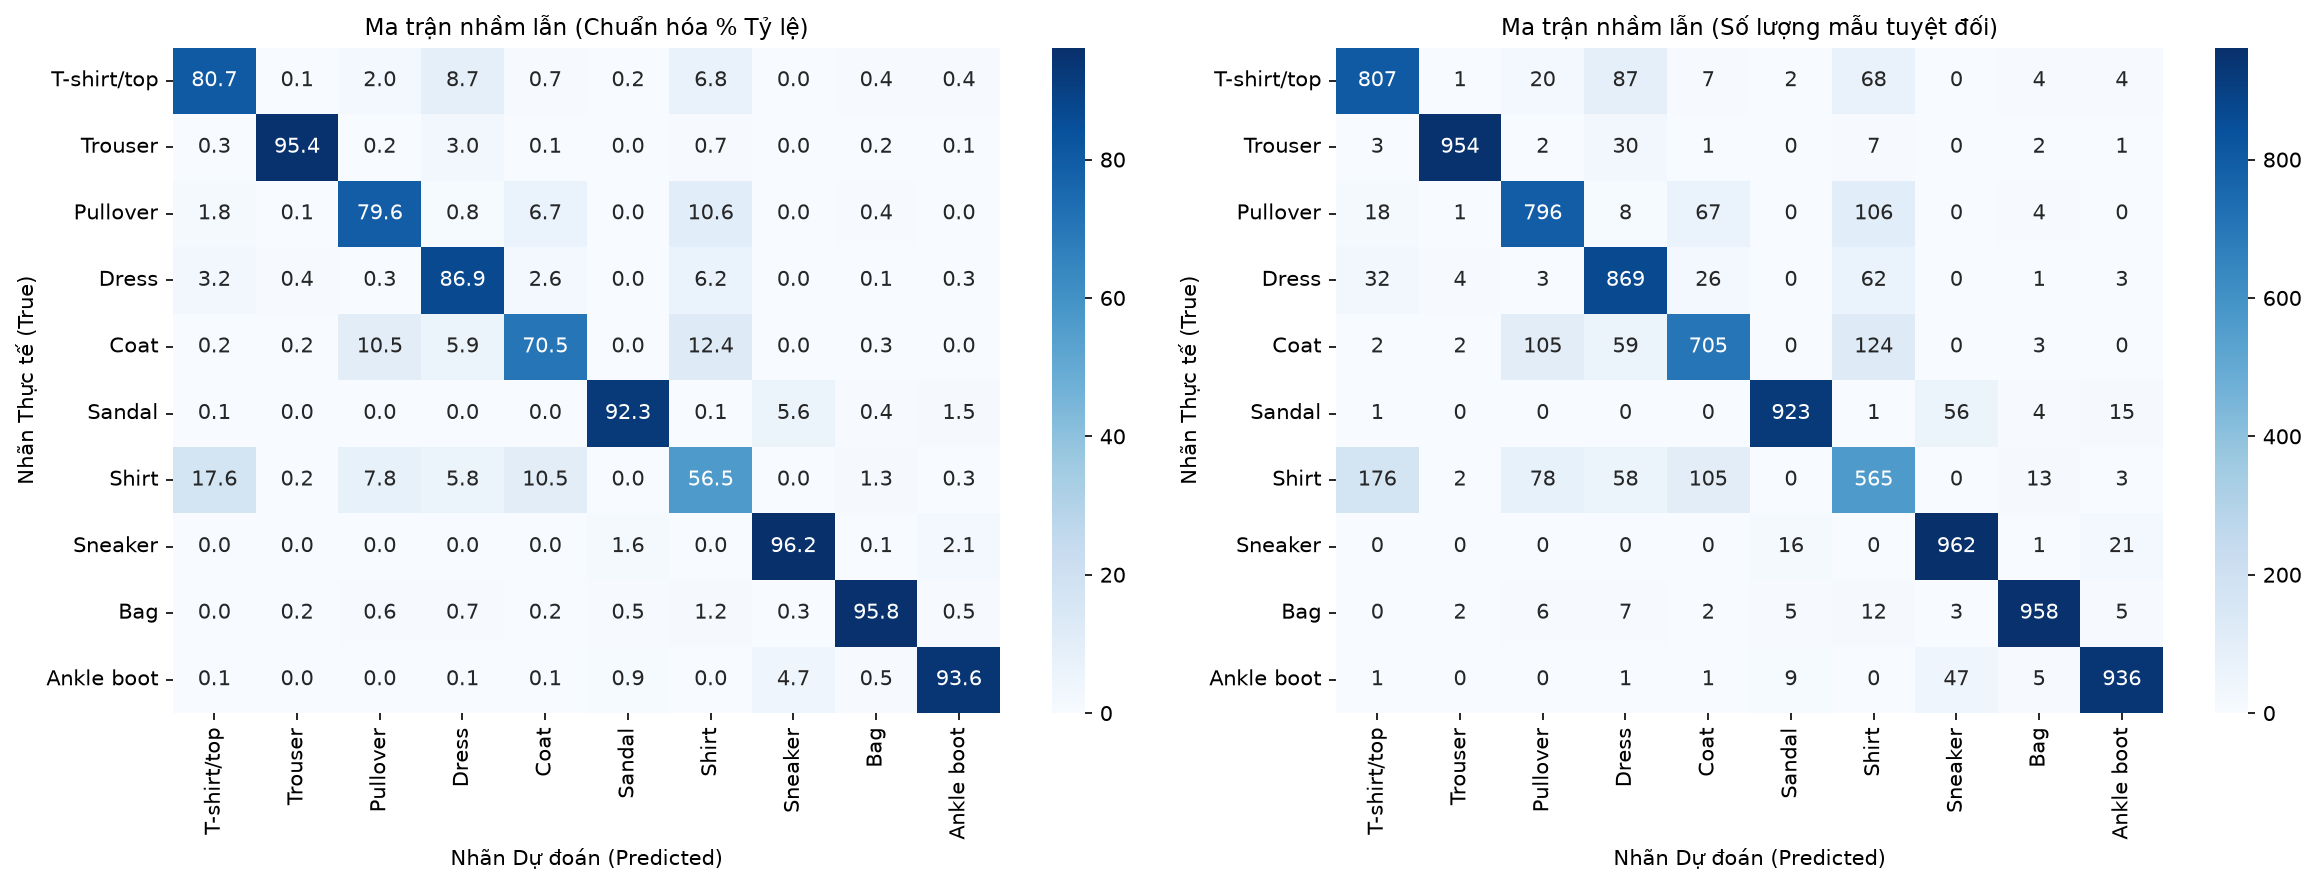

In [14]:
# 7.2 Tính toán và vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=150)

# Heatmap tỷ lệ chuẩn hóa (%)
sns.heatmap(cm_norm * 100, annot=True, fmt=".1f", cmap="Blues", cbar=True,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax1)
ax1.set_title("Ma trận nhầm lẫn (Chuẩn hóa % Tỷ lệ)", fontsize=11)
ax1.set_xlabel("Nhãn Dự đoán (Predicted)", fontsize=10)
ax1.set_ylabel("Nhãn Thực tế (True)", fontsize=10)

# Heatmap số lượng mẫu
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax2)
ax2.set_title("Ma trận nhầm lẫn (Số lượng mẫu tuyệt đối)", fontsize=11)
ax2.set_xlabel("Nhãn Dự đoán (Predicted)", fontsize=10)
ax2.set_ylabel("Nhãn Thực tế (True)", fontsize=10)

plt.tight_layout()
plt.show()


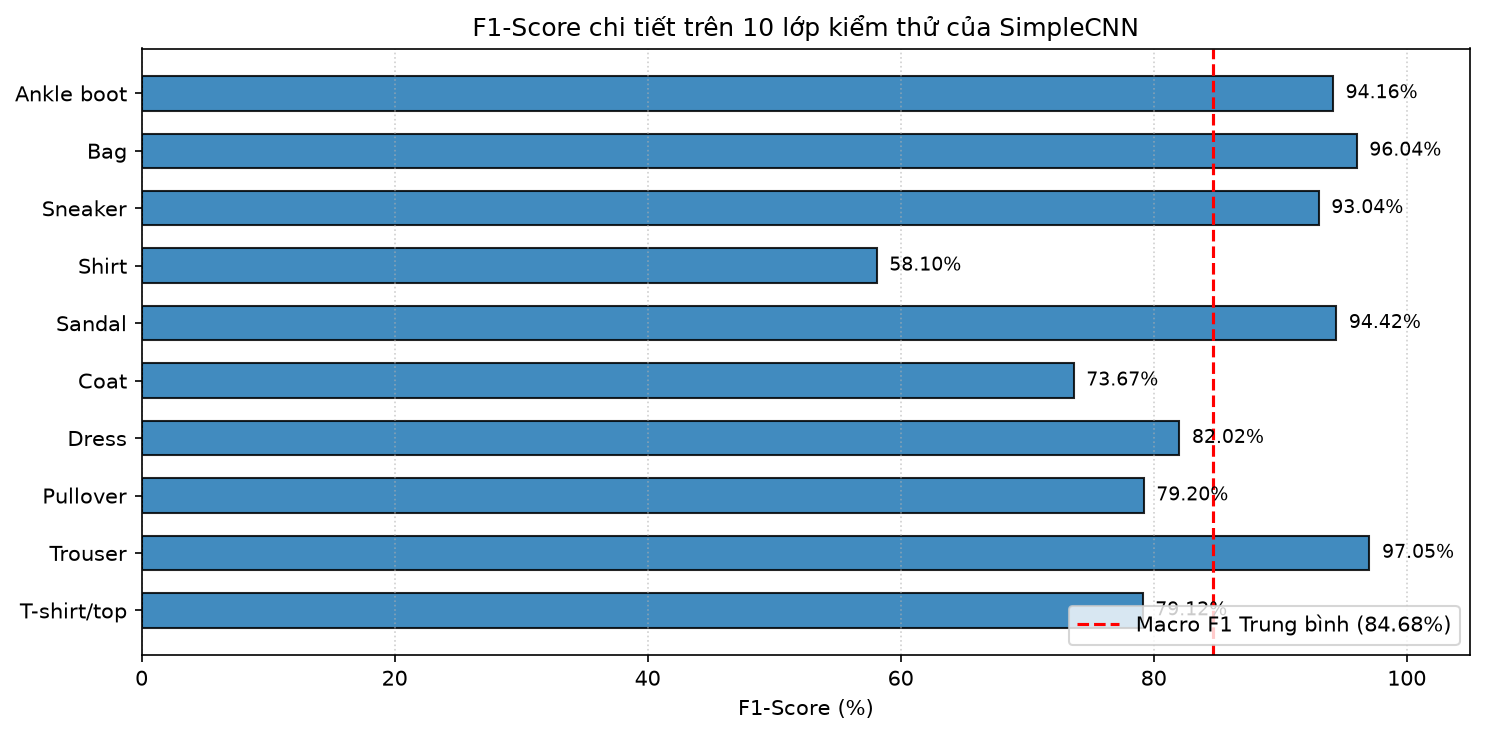

In [15]:
# 7.3 So sánh F1-Score chi tiết từng lớp (Per-Class F1-Score)
f1_per_class = f1_score(y_true, y_pred, average=None)

plt.figure(figsize=(10, 5), dpi=150)
y_pos = np.arange(len(CLASS_NAMES))
bars = plt.barh(y_pos, f1_per_class * 100, color="#1f77b4", alpha=0.85, edgecolor="black", height=0.6)
plt.axvline(macro_f1 * 100, color="red", linestyle="--", lw=1.5, label=f"Macro F1 Trung bình ({macro_f1*100:.2f}%)")
plt.yticks(y_pos, CLASS_NAMES, fontsize=10)
plt.xlabel("F1-Score (%)", fontsize=10)
plt.title("F1-Score chi tiết trên 10 lớp kiểm thử của SimpleCNN", fontsize=12)
plt.xlim(0, 105)
plt.grid(True, axis="x", linestyle=":", alpha=0.6)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", va="center", fontsize=9)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


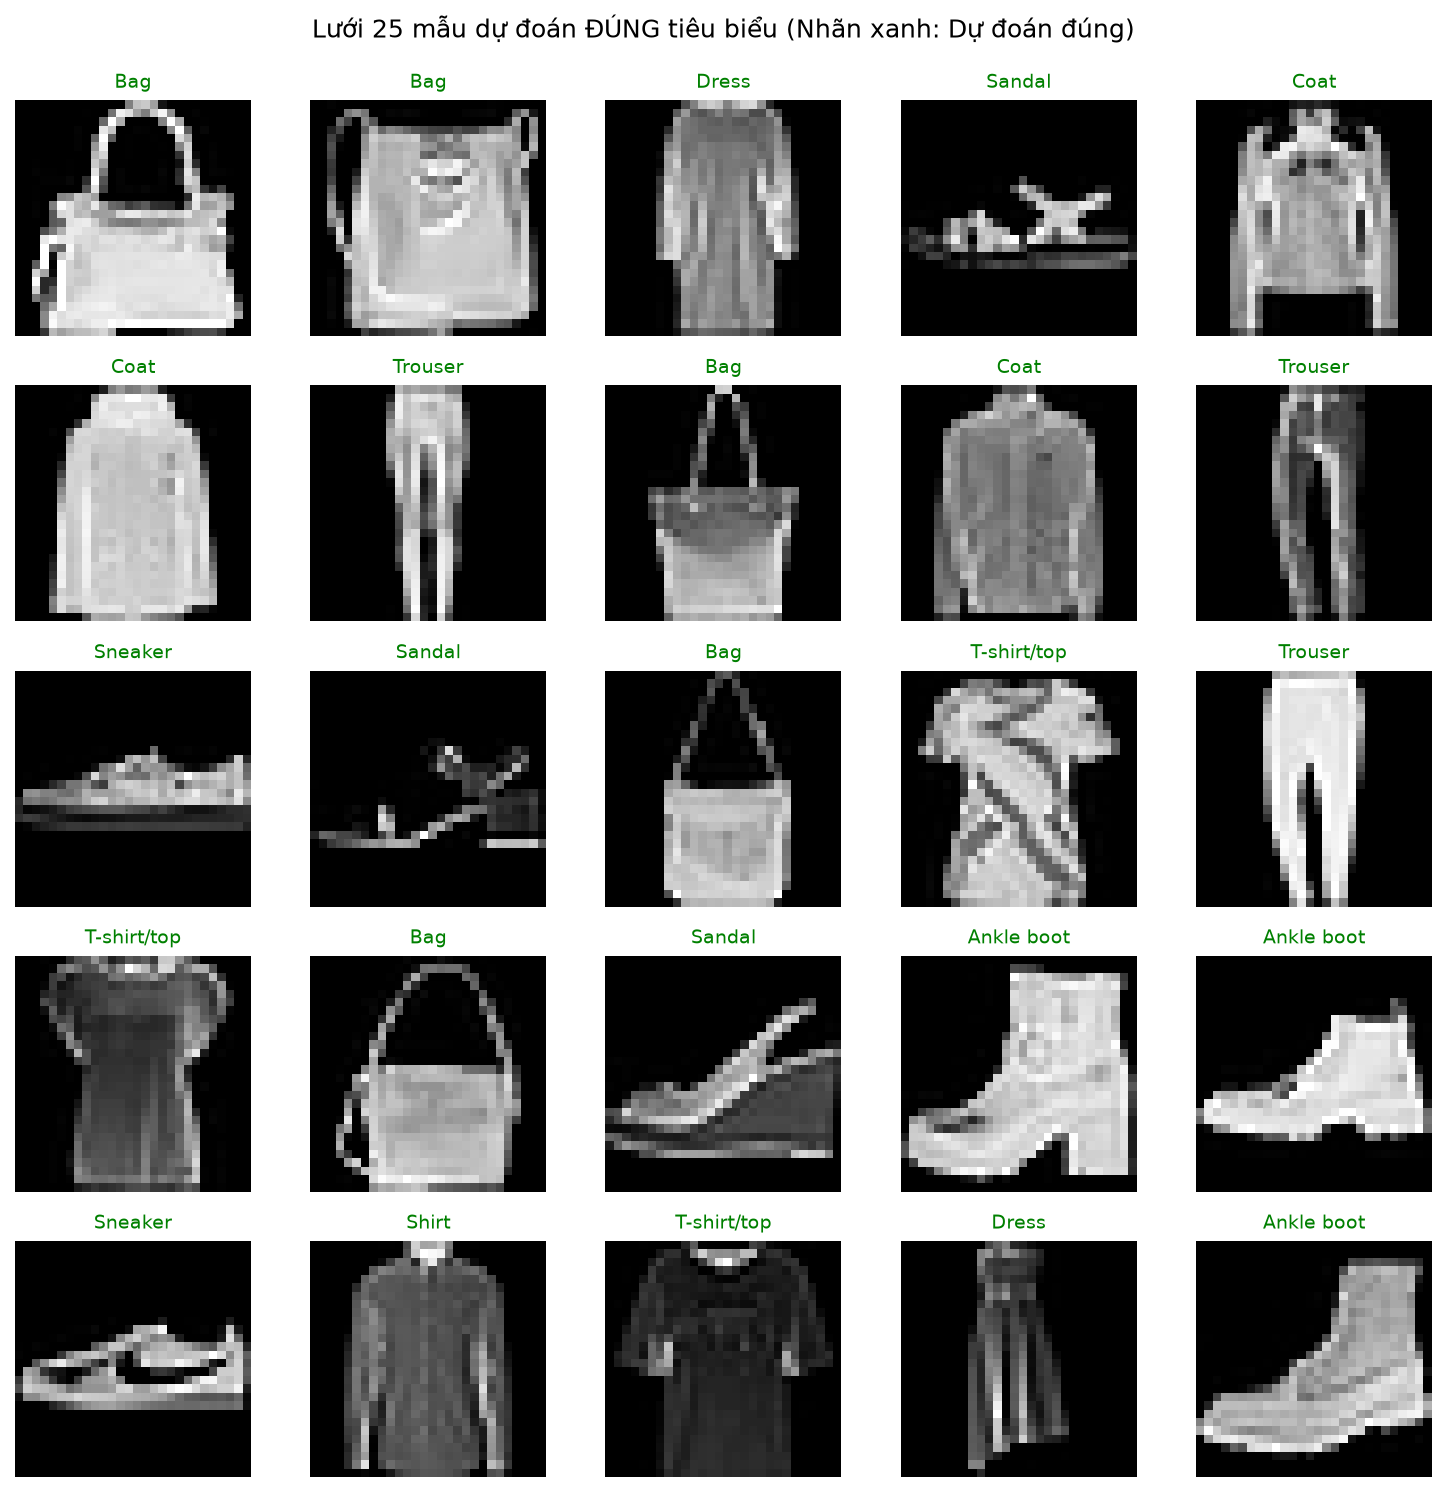

In [16]:
# 7.4 Trực quan hóa các mẫu dự đoán đúng tiêu biểu (Correct Predictions Grid)
correct_indices = np.where(y_true == y_pred)[0]
np.random.seed(SEED)
sample_correct = np.random.choice(correct_indices, size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(10, 10), dpi=150)
for i, ax in enumerate(axes.flat):
    s_idx = sample_correct[i]
    img, _ = test_dataset[s_idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{CLASS_NAMES[y_pred[s_idx]]}", color="green", fontsize=9)
    ax.axis("off")

plt.suptitle("Lưới 25 mẫu dự đoán ĐÚNG tiêu biểu (Nhãn xanh: Dự đoán đúng)", fontsize=12, y=0.99)
plt.tight_layout()
plt.show()


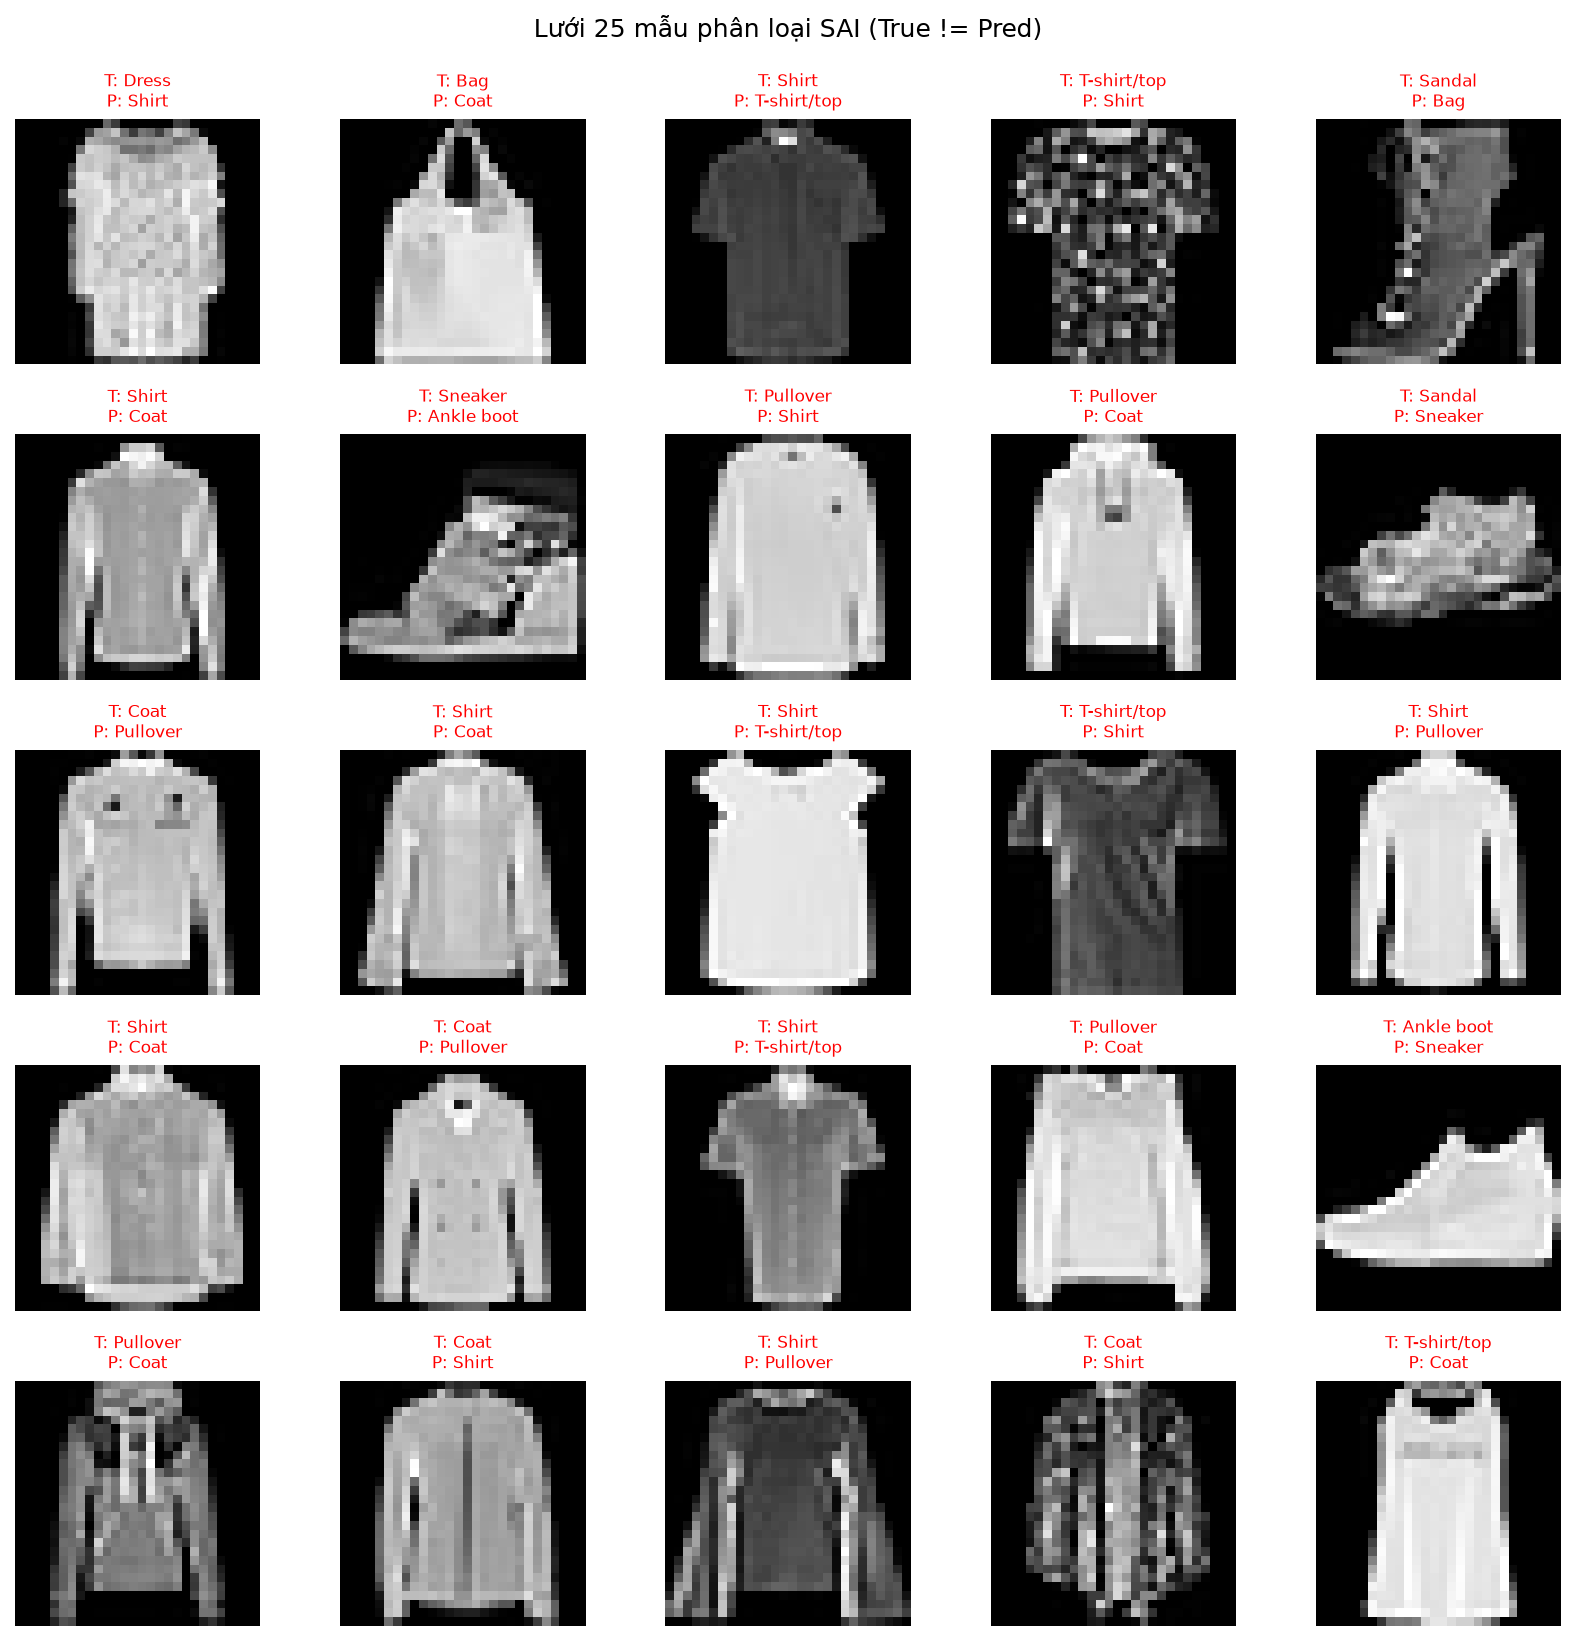


TOP 6 CẶP LỚP DỄ NHẦM LẪN NHẤT TRÊN TẬP TEST (TÍNH TỪ CONFUSION MATRIX):
1. Thực tế: Shirt        -> Nhầm sang: T-shirt/top  (176 mẫu lỗi)
2. Thực tế: Coat         -> Nhầm sang: Shirt        (124 mẫu lỗi)
3. Thực tế: Pullover     -> Nhầm sang: Shirt        (106 mẫu lỗi)
4. Thực tế: Coat         -> Nhầm sang: Pullover     (105 mẫu lỗi)
5. Thực tế: Shirt        -> Nhầm sang: Coat         (105 mẫu lỗi)
6. Thực tế: T-shirt/top  -> Nhầm sang: Dress        (87 mẫu lỗi)


In [17]:
# 7.5 Phân tích mẫu phân loại sai (Error Analysis) & Top cặp lớp nhầm lẫn
error_indices = np.where(y_true != y_pred)[0]
np.random.seed(SEED)
sample_errors = np.random.choice(error_indices, size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(11, 11), dpi=150)
for i, ax in enumerate(axes.flat):
    s_idx = sample_errors[i]
    img, _ = test_dataset[s_idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"T: {CLASS_NAMES[y_true[s_idx]]}\nP: {CLASS_NAMES[y_pred[s_idx]]}", color="red", fontsize=8)
    ax.axis("off")

plt.suptitle("Lưới 25 mẫu phân loại SAI (True != Pred)", fontsize=12, y=0.99)
plt.tight_layout()
plt.show()

# Tự động trích xuất các cặp nhầm lẫn nghiêm trọng nhất
cm_err = cm.copy()
np.fill_diagonal(cm_err, 0)
print("\nTOP 6 CẶP LỚP DỄ NHẦM LẪN NHẤT TRÊN TẬP TEST (TÍNH TỪ CONFUSION MATRIX):")
for rank in range(1, 7):
    idx_p = np.unravel_index(np.argmax(cm_err), cm_err.shape)
    print(f"{rank}. Thực tế: {CLASS_NAMES[idx_p[0]]:<12} -> Nhầm sang: {CLASS_NAMES[idx_p[1]]:<12} ({cm_err[idx_p]} mẫu lỗi)")
    cm_err[idx_p] = 0


---
## PHẦN 8: TỔNG KẾT VÀ BÀI HỌC KINH NGHIỆM
1. **Kết quả đạt được:**
   - Hoàn thành toàn diện các yêu cầu kỹ thuật: Tensors, Autograd, Optimization loop, Dataset loading, Stratified splitting, Modeling, Checkpointing, Dynamic Evaluation & Error Analysis.
   - **SimpleCNN** đạt độ chính xác **84.75%** trên 10.000 mẫu Test độc lập và **Macro F1 đạt 0.8468** (vượt trội hơn hẳn so với BaselineMLP đạt 82.07% và F1 0.8204).
   - Kiến trúc tích chập kết hợp Global Average Pooling (GAP) giúp giảm số lượng tham số từ **203.530** xuống còn **38.122** (giảm 5.3 lần), đồng thời triệt tiêu hiện tượng Overfitting hiệu quả.
2. **Bản chất các ca phân loại sai (Error Patterns):**
   - Sự nhầm lẫn tập trung chủ yếu ở cụm áo thân trên: `Shirt` $\rightarrow$ `T-shirt/top` (176 mẫu), `Coat` $\rightarrow$ `Shirt` (124 mẫu), `Pullover` $\rightarrow$ `Shirt` (106 mẫu).
   - *Nguyên nhân cốt lõi:* Độ phân giải ảnh $28 \times 28$ grayscale làm mờ nhạt các chi tiết quan trọng (hàng cúc áo sơ mi, chất liệu vải len/dạ, đường xẻ vạt áo khoác), khiến mô hình chỉ dựa vào hình dáng bao ngoài (silhouette).
   - Ngược lại, các lớp có cấu trúc góc cạnh hoặc hình dáng đặc trưng như `Trouser` (95.40%), `Sneaker` (96.20%), `Bag` (95.80%) đạt độ chính xác rất cao.
3. **Đề xuất hướng phát triển tiếp theo:**
   - Áp dụng các kỹ thuật Data Augmentation nâng cao: RandomAffine, Mixup, CutMix.
   - Nâng cấp mạng với kết nối phần dư (Residual Connections - ResNet) hoặc cơ chế Attention (CBAM) để tập trung vào các vùng chi tiết viền áo.
